# Eksperimen Pribadi — Tugas 3 Bagian B.i: Embedding Judul vs Teks Lengkap

> "Membandingkan embeddings judul/headline vs embeddings teks lengkap (full-text)."

**Pertanyaan:** apakah judul saja (pendek, padat) memberi sinyal lebih baik, sama, atau lebih buruk daripada isi artikel penuh?

| Varian | Teks yang di-encode |
|---|---|
| **judul** | hanya `title` (1 potongan, maks 64 token) |
| **isi** | `title. full_text` dengan chunking (cache dari notebook Bagian B; judul hanya ~1 dari ~800 kata) |
| **judul+isi** | gabungan fitur dari kedua varian (PCA masing-masing) |

Dua model transformer yang sama seperti Bagian B (MiniLM, FinBERT), beku (tanpa fine-tuning). Hanya **teks masukan** yang berbeda; protokol evaluasi, split, dan PCA identik.

**Hipotesis untuk diuji (bukan kesimpulan):** judul mungkin lebih padat sentimen dan bebas dari pengenceran/pemotongan, sedangkan isi memuat lebih banyak informasi tapi lebih berisik.

**Prasyarat:** cache `isi` dari Bagian B ada di `cache_embeddings/`. Kalau belum ada (mis. FinBERT masih di Kaggle), bagian itu otomatis dilewati dan hanya varian judul yang jalan.

## 0. Setup

In [2]:
import sys, re, json, time, warnings
sys.dont_write_bytecode = True
from pathlib import Path
import numpy as np, pandas as pd
import matplotlib.pyplot as plt
import torch
from transformers import AutoTokenizer, AutoModel, AutoModelForSequenceClassification
from sklearn.preprocessing import StandardScaler
from sklearn.decomposition import PCA
from sklearn.linear_model import Ridge
from sklearn.ensemble import RandomForestRegressor, GradientBoostingRegressor
from sklearn.metrics import balanced_accuracy_score, matthews_corrcoef

warnings.filterwarnings("ignore")
sys.path.append("..")
from eval_utils import evaluate, naive_baselines

EXPORT_DIR = Path("../../data/export")
CACHE_DIR = Path("cache_embeddings"); CACHE_DIR.mkdir(exist_ok=True)
SEED = 42
DEVICE = "cuda" if torch.cuda.is_available() else ("mps" if torch.backends.mps.is_available() else "cpu")
torch.set_num_threads(max(1, torch.get_num_threads()))
pd.set_option("display.width", 170); pd.set_option("display.max_columns", 40)
print("device:", DEVICE)

device: mps


## 1. Muat data dan split

In [3]:
articles = pd.read_parquet(EXPORT_DIR / "articles.parquet").sort_values("article_id").reset_index(drop=True)
prices   = pd.read_parquet(EXPORT_DIR / "prices_daily.parquet")
sent     = pd.read_parquet(EXPORT_DIR / "sentiment_daily.parquet")
splits   = json.loads((EXPORT_DIR / "splits.json").read_text())

KURS_COLS = ["kurs_lag1", "kurs_lag2", "kurs_lag3", "kurs_lag4", "kurs_lag5", "kurs_roll_mean5", "kurs_roll_std5"]
LEX_COLS = [c for c in sent.columns if c not in ("date", "news_count")]
assert len(KURS_COLS) == 7 and len(LEX_COLS) == 16

daily = (prices.merge(sent[["date", "news_count"] + LEX_COLS], on="date", how="left")
               .sort_values("date").reset_index(drop=True))
assert daily[LEX_COLS].notna().all().all()
for s in ("train", "val", "test"):
    assert (daily["split"] == s).sum() == splits[s]["n"]
tr = (daily["split"] == "train").to_numpy(); va = (daily["split"] == "val").to_numpy(); te = (daily["split"] == "test").to_numpy()
y = daily["target"].to_numpy()

articles["split"] = articles["aligned_trading_date"].map(dict(zip(daily["date"], daily["split"])))
articles["text_raw"] = articles["title"].fillna("").str.strip() + ". " + articles["full_text"].fillna("").str.strip()
print("baris per split:", tr.sum(), va.sum(), te.sum())
print(articles["split"].value_counts(dropna=False).to_string())

baris per split: 836 178 180
split
train    2489
test     1220
val       619
NaN         4


## 2. Embedding judul (cepat) dan memuat embedding isi (dari cache Bagian B)

Judul rata-rata hanya ~12 kata, jadi encoding ribuan judul selesai dalam hitungan menit bahkan di CPU.

In [4]:
@torch.no_grad()
def encode_chunks(chunks, cfg):
    tok = AutoTokenizer.from_pretrained(cfg["name"])
    Cls = AutoModelForSequenceClassification if cfg["logits"] else AutoModel
    model = Cls.from_pretrained(cfg["name"]).to(DEVICE).eval()
    order = np.argsort([len(c) for c in chunks])               # urut panjang → padding hemat
    H = np.zeros((len(chunks), model.config.hidden_size), np.float32)
    P = np.zeros((len(chunks), model.config.num_labels), np.float32) if cfg["logits"] else None
    n_trunc = 0; t0 = time.time()
    for b in range(0, len(order), cfg["batch"]):
        idx = order[b:b + cfg["batch"]]
        enc = tok([chunks[i] for i in idx], padding=True, truncation=True,
                  max_length=cfg["max_len"], return_tensors="pt")
        n_trunc += int((enc["attention_mask"].sum(1) >= cfg["max_len"]).sum())
        enc = {k: v.to(DEVICE) for k, v in enc.items()}
        if cfg["logits"]:
            out = model(**enc, output_hidden_states=True)
            hs = out.hidden_states[-1]; P[idx] = torch.softmax(out.logits, -1).float().cpu().numpy()
        else:
            hs = model(**enc).last_hidden_state
        m = enc["attention_mask"].unsqueeze(-1).to(hs.dtype)
        H[idx] = ((hs * m).sum(1) / m.sum(1)).float().cpu().numpy()
        if (b // cfg["batch"]) % 50 == 0:
            done = b + len(idx); el = time.time() - t0
            print(f"  {done}/{len(order)} chunk | {el:.0f}s | sisa ~{el / done * (len(order) - done):.0f}s", flush=True)
    labels = {int(k): v.lower() for k, v in model.config.id2label.items()} if cfg["logits"] else None
    return H, P, labels, n_trunc / len(chunks)

In [5]:
FULL = {   # cache hasil notebook Bagian B
    "MiniLM":  dict(name="sentence-transformers/all-MiniLM-L6-v2",  file="MiniLM_cw160_mc5_ml256.npz",  logits=False),
    "FinBERT": dict(name="ProsusAI/finbert", file="FinBERT_cw300_mc2_ml512.npz", logits=True),
}
TITLE = {
    "MiniLM":  dict(name="sentence-transformers/all-MiniLM-L6-v2",  max_len=64, batch=64, logits=False),
    "FinBERT": dict(name="ProsusAI/finbert", max_len=64, batch=64, logits=True),
}

titles = articles["title"].fillna("").str.strip().tolist()
tw = pd.Series(titles).str.split().map(len)
print(f"judul: rata-rata {tw.mean():.1f} kata (median {tw.median():.0f}, maks {tw.max()}) | judul kosong: {(tw == 0).sum()}")

def embed_titles(tag):
    cfg = TITLE[tag]; f = CACHE_DIR / f"title_{tag}_ml{cfg['max_len']}.npz"
    if f.exists():
        z = np.load(f, allow_pickle=True); print(f"{tag} judul: dimuat dari cache {f.name}")
        return z["A"], (z["P"] if cfg["logits"] else None), (z["labels"].item() if cfg["logits"] else None)
    print(f"{tag} judul: encode {len(titles):,} judul di {DEVICE} ...")
    H, P, labels, trunc = encode_chunks(titles, cfg)
    print(f"{tag} judul: terpotong max_len = {trunc:.1%}")
    A = H / np.linalg.norm(H, axis=1, keepdims=True).clip(1e-12)
    np.savez(f, A=A, P=(P if cfg["logits"] else np.zeros((len(A), 1))), labels=np.array(labels, dtype=object))
    return A, P, labels

def load_full(tag):
    f = CACHE_DIR / FULL[tag]["file"]
    if not f.exists():
        print(f"{tag} isi: cache {f.name} BELUM ADA -> varian isi dilewati"); return None
    z = np.load(f, allow_pickle=True); lg = FULL[tag]["logits"]
    print(f"{tag} isi: dimuat dari cache {f.name}")
    return z["A"], (z["P"] if lg else None), (z["labels"].item() if lg else None)

EMB = {}      # (model, varian) -> (A, P, labels)
for tag in ("MiniLM", "FinBERT"):
    EMB[(tag, "judul")] = embed_titles(tag)
    full = load_full(tag)
    if full is not None: EMB[(tag, "isi")] = full
print({k: v[0].shape for k, v in EMB.items()})

judul: rata-rata 12.7 kata (median 13, maks 16) | judul kosong: 0
MiniLM judul: dimuat dari cache title_MiniLM_ml64.npz
MiniLM isi: dimuat dari cache MiniLM_cw160_mc5_ml256.npz
FinBERT judul: dimuat dari cache title_FinBERT_ml64.npz
FinBERT isi: dimuat dari cache FinBERT_cw300_mc2_ml512.npz
{('MiniLM', 'judul'): (4332, 384), ('MiniLM', 'isi'): (4332, 384), ('FinBERT', 'judul'): (4332, 768), ('FinBERT', 'isi'): (4332, 768)}


### Seberapa beda representasinya?
Cosine antara vektor judul dan vektor isi **dari artikel yang sama** (1 = identik arah). Nilai rendah berarti judul dan isi menangkap hal yang berbeda, jadi menggabungkannya masuk akal.

In [6]:
def unit(A): return A / np.linalg.norm(A, axis=1, keepdims=True).clip(1e-12)
for tag in ("MiniLM", "FinBERT"):
    if (tag, "isi") in EMB:
        cs = (unit(EMB[(tag, "judul")][0]) * unit(EMB[(tag, "isi")][0])).sum(1)
        print(f"{tag:8s} cosine judul-isi (artikel sama): rata-rata {cs.mean():.3f} | min {cs.min():.3f} | maks {cs.max():.3f}")

MiniLM   cosine judul-isi (artikel sama): rata-rata 0.671 | min 0.112 | maks 0.889
FinBERT  cosine judul-isi (artikel sama): rata-rata 0.740 | min 0.170 | maks 0.913


## 3. Artikel → hari → fitur
Sama dengan Bagian B: rata-rata harian, PCA (hanya hari train) k = 5/10/20, dan 6 skor sentimen FinBERT harian. Tambahan: varian **judul+isi** = gabungan PCA k=10 dari masing-masing.

In [7]:
KS = (5, 10, 20)

def pca_daily(A, kmax=max(KS)):
    keep = articles["split"].notna().to_numpy()
    emb = pd.DataFrame(A[keep]); emb["date"] = articles.loc[keep, "aligned_trading_date"].to_numpy()
    d = emb.groupby("date").mean().reindex(daily["date"])
    has = d.notna().all(axis=1).to_numpy(); D = d.to_numpy(dtype=float)
    pca = PCA(n_components=kmax, random_state=SEED).fit(D[tr & has])        # TRAIN saja
    Z = np.zeros((len(daily), kmax)); Z[has] = pca.transform(D[has])
    return {k: Z[:, :k] for k in KS}, int(has.sum()), float(pca.explained_variance_ratio_.sum())

def finbert_daily(P, labels):
    idx = {v: k for k, v in labels.items()}
    pos, neg, neu = P[:, idx["positive"]], P[:, idx["negative"]], P[:, idx["neutral"]]
    keep = articles["split"].notna().to_numpy()
    df = pd.DataFrame({"fb_pos": pos, "fb_neg": neg, "fb_neu": neu, "net": pos - neg})[keep]
    df["date"] = articles.loc[keep, "aligned_trading_date"].to_numpy()
    g = df.groupby("date")
    out = pd.DataFrame({"fb_pos_mean": g["fb_pos"].mean(), "fb_neg_mean": g["fb_neg"].mean(),
                        "fb_neu_mean": g["fb_neu"].mean(), "fb_net_mean": g["net"].mean(),
                        "fb_net_min": g["net"].min(), "fb_net_max": g["net"].max()})
    return out.reindex(daily["date"]).fillna(0.0).to_numpy()

In [8]:
FEATS, FBS = {}, {}
for (tag, var), (A, P, labels) in EMB.items():
    Zs, n_days, evr = pca_daily(A)
    for k, Z in Zs.items():
        FEATS[f"C  kurs+{tag}-{var}-emb k={k}"] = Z
    if tag == "FinBERT":
        FBS[var] = finbert_daily(P, labels)
    print(f"{tag:8s} {var:6s} | hari ada berita {n_days} | EVR 20 komponen {evr:.3f}")

for tag in ("MiniLM", "FinBERT"):                        # judul+isi (gabungan)
    kj, ki = f"C  kurs+{tag}-judul-emb k=10", f"C  kurs+{tag}-isi-emb k=10"
    if kj in FEATS and ki in FEATS:
        FEATS[f"C  kurs+{tag}-judul+isi-emb k=10+10"] = np.hstack([FEATS[kj], FEATS[ki]])
if "judul" in FBS and "isi" in FBS:
    FBS["judul+isi"] = np.hstack([FBS["judul"], FBS["isi"]])
print(len(FEATS), "set embedding |", list(FBS))

MiniLM   judul  | hari ada berita 1073 | EVR 20 komponen 0.434
MiniLM   isi    | hari ada berita 1073 | EVR 20 komponen 0.606
FinBERT  judul  | hari ada berita 1073 | EVR 20 komponen 0.610
FinBERT  isi    | hari ada berita 1073 | EVR 20 komponen 0.795
14 set embedding | ['judul', 'isi', 'judul+isi']


## 4. Protokol evaluasi (identik dengan Bagian A dan B)

In [9]:
MODELS = {
    "Ridge": lambda s: Ridge(alpha=10.0),
    "RandForest": lambda s: RandomForestRegressor(n_estimators=200, min_samples_leaf=5, max_features=0.5, n_jobs=-1, random_state=s),
    "GradBoost": lambda s: GradientBoostingRegressor(n_estimators=150, max_depth=2, learning_rate=0.03, subsample=0.8, random_state=s),
}
SEEDS = (0, 1, 2)

def direction_metrics(y_true, y_pred):
    m = y_true != 0
    t, p = y_true[m] > 0, y_pred[m] > 0
    return {"BalAcc": balanced_accuracy_score(t, p), "MCC": matthews_corrcoef(t, p)}

def fit_predict(X):
    Xs = StandardScaler().fit(X[tr]).transform(X)
    preds = {}
    for name, make in MODELS.items():
        seeds = (0,) if name == "Ridge" else SEEDS
        preds[name] = np.mean([make(s).fit(Xs[tr], y[tr]).predict(Xs) for s in seeds], axis=0)
    return preds

rows = []
def run(set_name, X):
    for mname, p in fit_predict(X).items():
        for sp, mask in (("val", va), ("test", te)):
            r = evaluate(y[mask], p[mask]); r.update(direction_metrics(y[mask], p[mask]))
            rows.append(dict(set=set_name, model=mname, split=sp, **r))

ret_today = daily["ret"].to_numpy(); base_rows = []
for sp, mask in (("val", va), ("test", te)):
    nb = naive_baselines(y[mask], ret_today[mask])
    nb["Konstan (mean train)"] = evaluate(y[mask], np.full(mask.sum(), y[tr].mean()))
    preds = {"Prediksi 0": np.zeros(mask.sum()), "Return kemarin": ret_today[mask],
             "Konstan (mean train)": np.full(mask.sum(), y[tr].mean())}
    for name, r in nb.items():
        r = dict(r); r.update(direction_metrics(y[mask], preds[name]))
        base_rows.append(dict(set=name, model="-", split=sp, **r))

In [10]:
KURS = daily[KURS_COLS].to_numpy(); LEX = daily[LEX_COLS].to_numpy()
run("A  kurs", KURS)
run("B  kurs+lexicon", np.hstack([KURS, LEX]))
for name, Z in FEATS.items():
    run(name, np.hstack([KURS, Z]))
for var, Z in FBS.items():
    run(f"C  kurs+FinBERT-{var}-sent", np.hstack([KURS, Z]))

res = pd.DataFrame(rows); base = pd.DataFrame(base_rows)
print("selesai:", res["set"].nunique(), "set x", res["model"].nunique(), "model")

selesai: 19 set x 3 model


## 5. Hasil

### 5.1 Pembanding tanpa model

In [11]:
cols = ["MAE", "RMSE", "DirAcc", "BalAcc", "MCC"]
base.pivot(index="set", columns="split", values=cols).round(5)

MAE              RMSE            DirAcc          BalAcc               MCC         
split                    test      val     test      val     test      val   test      val     test      val
set                                                                                                         
Konstan (mean train)  0.00218  0.00246  0.00289  0.00338  0.59091  0.53409  0.500  0.50000  0.00000  0.00000
Prediksi 0            0.00221  0.00247  0.00291  0.00338  0.00000  0.00000  0.500  0.50000  0.00000  0.00000
Return kemarin        0.00308  0.00347  0.00398  0.00461  0.54545  0.50568  0.539  0.50908  0.07754  0.01816

### 5.2 Rata-rata 3 model per set fitur
`dRMSE%` = selisih terhadap A pada split yang sama (negatif = lebih baik dari A).

In [12]:
mean_tbl = res.groupby(["set", "split"])[["RMSE", "DirAcc", "BalAcc", "MCC"]].mean().unstack("split")
a_rmse = mean_tbl.loc["A  kurs", "RMSE"]
for sp in ("val", "test"):
    mean_tbl[("dRMSE%", sp)] = (mean_tbl[("RMSE", sp)] / a_rmse[sp] - 1) * 100
mean_tbl = mean_tbl.sort_values(("RMSE", "val"))
mean_tbl.round(5)

RMSE            DirAcc            BalAcc               MCC            dRMSE%         
split                                     test      val     test      val     test      val     test      val      val     test
set                                                                                                                            
C  kurs+FinBERT-judul-emb k=20         0.00299  0.00340  0.48106  0.51894  0.51389  0.53122  0.03376  0.06575 -1.12583 -1.26881
C  kurs+FinBERT-judul+isi-sent         0.00300  0.00340  0.47159  0.48295  0.52796  0.50272  0.07360  0.00133 -0.93291 -0.93657
C  kurs+FinBERT-isi-emb k=10           0.00295  0.00341  0.48295  0.50758  0.52475  0.52681  0.04366  0.06447 -0.77822 -2.60402
C  kurs+FinBERT-isi-emb k=20           0.00300  0.00341  0.46023  0.49621  0.50125  0.50865 -0.00096  0.01769 -0.70417 -0.82364
C  kurs+FinBERT-judul+isi-emb k=10+10  0.00295  0.00341  0.50758  0.50379  0.52422  0.51704  0.04741  0.03583 -0.66786 -2.54843
C  kurs+FinBERT-judul-emb k=5          0.00303  0.00341  0.42424  0.51515  0.49359  0.53390 -0.01937  0.08240 -0.55785  0.20370
C  kurs+FinBERT-isi-emb k=5            0.00300  0.00341  0.41477  0.48864  0.48486  0.50701 -0.04952  0.01545 -0.55603 -0.79602
C  kurs+MiniLM-isi-emb k=20            0.00297  0.00342  0.45644  0.52083  0.50873  0.53300  0.01179  0.07120 -0.35585 -1.98838
C  kurs+FinBERT-judul-sent             0.00305  0.00342  0.43750  0.48485  0.51620  0.50683  0.05783  0.01531 -0.30585  0.74556
C  kurs+MiniLM-isi-emb k=5             0.00301  0.00343  0.47159  0.50947  0.52796  0.52443  0.05715  0.05664 -0.21866 -0.69946
C  kurs+FinBERT-judul-emb k=10         0.00300  0.00343  0.48864  0.51326  0.53241  0.52954  0.07588  0.06756 -0.17867 -0.84603
C  kurs+MiniLM-isi-emb k=10            0.00300  0.00343  0.45644  0.50758  0.51371  0.52474  0.01940  0.05904 -0.16511 -0.86932
C  kurs+FinBERT-isi-sent               0.00303  0.00343  0.45076  0.48106  0.52101  0.50251  0.05447 -0.00515 -0.05899  0.10689
A  kurs                                0.00303  0.00343  0.40720  0.47159  0.49769  0.49728 -0.03028 -0.01454  0.00000  0.00000
C  kurs+MiniLM-judul-emb k=10          0.00304  0.00343  0.42614  0.48864  0.49448  0.50727 -0.02271  0.01966  0.02365  0.26583
C  kurs+MiniLM-judul+isi-emb k=10+10   0.00299  0.00344  0.45265  0.48485  0.49697  0.50164 -0.01486  0.00213  0.07230 -1.24576
C  kurs+MiniLM-judul-emb k=5           0.00305  0.00344  0.40341  0.49432  0.48024  0.51155 -0.09798  0.02815  0.17921  0.88481
C  kurs+MiniLM-judul-emb k=20          0.00298  0.00345  0.42803  0.48864  0.48184  0.50493 -0.05249  0.01190  0.32284 -1.61231
B  kurs+lexicon                        0.00301  0.00346  0.44318  0.45644  0.49181  0.47557 -0.02755 -0.04702  0.62909 -0.47218

### 5.3 Inti B.i: judul vs isi, berpasangan
`judul_vs_isi%` = (RMSE judul / RMSE isi − 1) × 100. **Negatif = judul lebih baik.** Dibaca per model dan per k; yang berarti hanya bila arahnya konsisten di val **dan** test.

In [13]:
m = mean_tbl["RMSE"].reset_index()
m = m[m["set"].str.contains(r"-(?:judul|isi)-(?:emb k=\d+|sent)$")].copy()
m["model"]  = m["set"].str.extract(r"kurs\+(\w+)-")[0]
m["varian"] = m["set"].str.extract(r"-(judul|isi)-")[0]
m["fitur"]  = np.where(m["set"].str.endswith("sent"), "sent", m["set"].str.extract(r"(k=\d+)$")[0])
cmp = m.pivot_table(index=["model", "fitur"], columns="varian", values=["val", "test"])
if ("val", "isi") in cmp.columns:
    for sp in ("val", "test"):
        cmp[("judul_vs_isi%", sp)] = (cmp[(sp, "judul")] / cmp[(sp, "isi")] - 1) * 100
cmp.round(6)

split              test                 val           judul_vs_isi%          
varian              isi     judul       isi     judul           val      test
model   fitur                                                                
FinBERT k=10   0.002949  0.003002  0.003407  0.003428      0.604250  1.804992
        k=20   0.003003  0.002989  0.003410  0.003395     -0.424651 -0.448867
        k=5    0.003004  0.003034  0.003415  0.003415     -0.001824  1.007733
        sent   0.003031  0.003050  0.003432  0.003423     -0.247009  0.637988
MiniLM  k=10   0.003001  0.003036  0.003428  0.003435      0.189074  1.145106
        k=20   0.002968  0.002979  0.003422  0.003445      0.681108  0.383699
        k=5    0.003007  0.003055  0.003426  0.003440      0.398741  1.595433

### 5.4 Per model (RMSE val)

In [14]:
pm = res[res["split"] == "val"].pivot(index="set", columns="model", values="RMSE")
pm["rata2"] = pm.mean(axis=1); pm.sort_values("rata2").round(6)

model,GradBoost,RandForest,Ridge,rata2
set,,,,
C kurs+FinBERT-judul-emb k=20,0.003392,0.003417,0.003377,0.003395
C kurs+FinBERT-judul+isi-sent,0.003390,0.003443,0.003373,0.003402
C kurs+FinBERT-isi-emb k=10,0.003399,0.003433,0.003390,0.003407
C kurs+FinBERT-isi-emb k=20,0.003403,0.003432,0.003394,0.003410
C kurs+FinBERT-judul+isi-emb k=10+10,0.003398,0.003435,0.003400,0.003411
C kurs+FinBERT-judul-emb k=5,0.003404,0.003454,0.003387,0.003415
C kurs+FinBERT-isi-emb k=5,0.003416,0.003446,0.003382,0.003415
C kurs+MiniLM-isi-emb k=20,0.003410,0.003468,0.003387,0.003422
C kurs+FinBERT-judul-sent,0.003395,0.003472,0.003403,0.003423


### 5.5 Diagnostik sentimen FinBERT harian: judul vs isi
Korelasi Spearman antara `fb_net_mean` (rata-rata P(pos) − P(neg) harian) dari judul dan dari isi, serta masing-masing dengan target. Korelasi dengan target hanya dihitung pada **hari train** yang punya berita (supaya val/test tidak "diintip").

In [15]:
from scipy.stats import spearmanr
has = (daily["news_count"] > 0).to_numpy()
NET = 3   # kolom fb_net_mean
for var in ("judul", "isi"):
    if var in FBS:
        rho, p = spearmanr(FBS[var][tr & has, NET], y[tr & has])
        print(f"FinBERT {var:6s} fb_net_mean vs target (train, hari berita): rho={rho:+.3f}  p={p:.3f}  n={int((tr & has).sum())}")
if "judul" in FBS and "isi" in FBS:
    rho, p = spearmanr(FBS["judul"][has, NET], FBS["isi"][has, NET])
    print(f"fb_net_mean judul vs isi (semua hari berita): rho={rho:+.3f}")

FinBERT judul  fb_net_mean vs target (train, hari berita): rho=+0.021  p=0.569  n=734
FinBERT isi    fb_net_mean vs target (train, hari berita): rho=-0.056  p=0.129  n=734
fb_net_mean judul vs isi (semua hari berita): rho=+0.500


### 5.6 Grafik

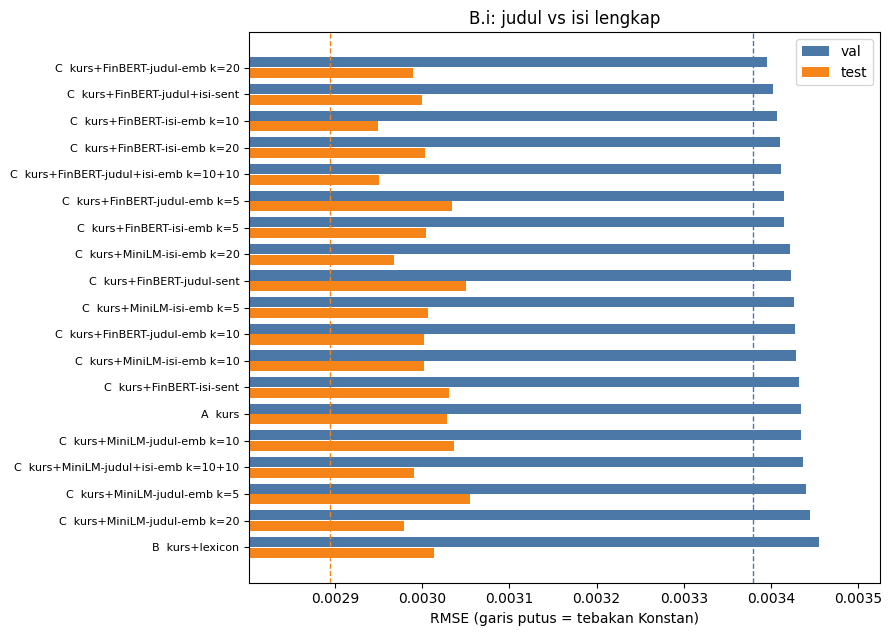

In [16]:
plot_df = mean_tbl["RMSE"].sort_values("val", ascending=False)
const = base[base["set"] == "Konstan (mean train)"].set_index("split")["RMSE"]
fig, ax = plt.subplots(figsize=(9, max(4, 0.34 * len(plot_df))))
yy = np.arange(len(plot_df))
ax.barh(yy + 0.2, plot_df["val"], height=0.38, label="val", color="#4C78A8")
ax.barh(yy - 0.2, plot_df["test"], height=0.38, label="test", color="#F58518")
ax.axvline(const["val"], color="#4C78A8", ls="--", lw=1); ax.axvline(const["test"], color="#F58518", ls="--", lw=1)
ax.set_yticks(yy); ax.set_yticklabels(plot_df.index, fontsize=8)
ax.set_xlim(plot_df.min().min() * 0.95, plot_df.max().max() * 1.02)
ax.set_xlabel("RMSE (garis putus = tebakan Konstan)"); ax.legend()
ax.set_title("B.i: judul vs isi lengkap"); plt.tight_layout(); plt.show()

## 6. Catatan metodologi
- **Judul vs isi tidak sepenuhnya terpisah:** varian `isi` memuat judul di awal potongan pertama (1 dari ~160-300 kata). Ini sengaja agar sama dengan Bagian B; judul praktis tenggelam di dalamnya.
- **Tidak ada kebocoran:** model beku; scaler dan PCA hanya di train; korelasi dengan target hanya pada data train.
- **Pembanding utama tetap baris Konstan**, bukan hanya Model A.
- Selisih kecil (< 1-2%) anggap noise kecuali konsisten di val, test, dan kedua model.

## 7. Kesimpulan 
1. Apakah judul konsisten lebih baik/buruk dari isi di val **dan** test, di MiniLM **dan** FinBERT? (lihat 5.3)
Tidak ada pemenang yang konsisten.

MiniLM: isi sedikit lebih baik di keenam sel.
FinBERT: campur. k=10 mendukung isi, k=20 mendukung judul di kedua split, k=5 dan sent bolak-balik.
Total 10 dari 14 sel condong ke isi, dengan selisih rata-rata di bawah 2%.

Kesimpulannya: isi sedikit unggul secara arah, tapi efeknya kecil dan tidak stabil, jadi belum bisa dibedakan dari noise.

2. Apakah judul+isi lebih baik dari salah satunya?
Embedding (FinBERT k=10+10): −0,67% / −2,55%. Hampir sama dengan FinBERT-isi k=10 saja (−0,78% / −2,60%), jadi tidak ada gain tambahan. Di MiniLM, judul+isi juga tidak lebih baik dari isi saja (sudah dibahas di pembacaan sebelumnya).
Sentimen (judul+isi-sent): −0,93% / −0,94%, konsisten di kedua split dan lebih baik dari masing-masing tunggalnya (judul-sent −0,31%/+0,75%, isi-sent −0,06%/+0,11%). Ini satu-satunya hasil di sini yang menarik, tapi selisihnya masih di bawah 1% dan ia hanya satu dari 17 set yang diuji, jadi perlakukan sebagai hipotesis, bukan temuan.

3. Untuk sentimen FinBERT: judul atau isi yang lebih berkorelasi dengan target (5.5)? Seberapa mirip keduanya?
Judul: rho = +0,021 (p = 0,57). Isi: rho = −0,056 (p = 0,13). Dengan n = 734, korelasi baru signifikan di sekitar |rho| ≥ 0,07, jadi tidak ada hubungan yang signifikan untuk keduanya. Tandanya pun berbeda.
Judul vs isi: rho = +0,50. Mereka separuh mirip, tapi belum redundan. Itu menjelaskan kenapa menggabungkan sentimen judul dan isi sedikit membantu di atas.

4. Apakah salah satu varian mengalahkan baris Konstan? Bagaimana BalAcc/MCC?
Tidak. Konstan val 0,00338 dan test 0,00289. Rata-rata terbaik: val 0,003395 (FinBERT-judul k=20), test 0,00295 (FinBERT-isi k=10 dan judul+isi k=10+10). Di tabel per model (5.4), beberapa kombinasi Ridge di val mencapai 0,003373–0,003377, setara dengan Konstan dalam batas pembulatan. Tabel per model untuk test tidak ada, jadi tidak bisa dikatakan mengalahkan. BalAcc/MCC tetap sekitar 0,5 / 0,03–0,07, masih dalam galat baku sekitar 0,07.

5. Implikasi untuk desain Model C akhir (judul saja lebih murah; apakah isi sepadan dengan biayanya?).